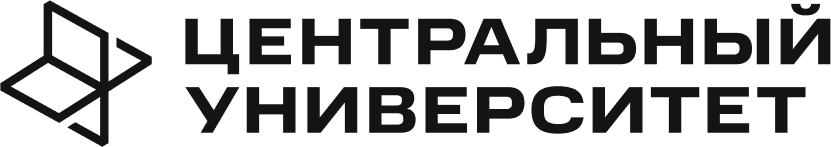

# Базы Данных. Итоговый Проект

Проект разделён на 2 части.

- 1 часть посвящена проектированию и данным.
- 2 часть посвящена алгоритмам и структурам данных, которые мы будем изучать далее.


В ближайшие несколько недель вам предстоит работать над первой частью, после её защиты будут выданы требования и описание второй части.

Данную часть проекта необходимо сдать в LMS для дистанционной проверки.

Предварительный дедлайн - 15.11.2026

## Описание проекта

Вам на почту пришло сообщение с индивидуальным вариантом, в котором дана уникальная бизнес-область с перечнем основных таблиц и дан аналитический запрос.

### **Задание**

Необходимо спроектировать и наполнить реляционную базу данных для решения аналитического SQL-запроса.


### **Для решения задачи вам необходимо:**

1. Спроектировать OLTP-схему:
   - концептуальная модель
   - логическая модель
   - физическая модель

    Перечень таблиц, предоставленный в рамках бизнес-области, является ориентировочным и может быть расширен или сокращён в зависимости от особенностей архитектуры, предлагаемой в конкретном решении. Допускается создание дополнительных справочников, технических таблиц, журналов версионирования, а также объединение или декомпозиция исходных сущностей, если это повышает логичность и целостность модели данных. Отклонения от базового набора таблиц должны быть обоснованы.

2. При необходимости можно спроектировать одну или несколько витрин данных, если они помогут упростить выполнение аналитического запроса. Витрина не является обязательной частью задания.

3. Сгенерировать и загрузить данные в разработанную схему БД.

    Для генерации реалистичных данных и DDL SQL-скриптов рекомендуется использовать LLM-модели.

    Данные должны быть живыми и разнообразными: ошибки, неточности, выбросы.
    В сумме в базе данных должно быть *несколько тысяч* строк (чем больше — тем лучше).

4. Реализовать SCD2 версионность как минимум для одной таблицы

    Таблица должна содержать поля даты начала и даты окончания версии (например, start_dttm, end_dttm).


### **Критерии оценивания**:

Схема данных (15 баллов)
  1. Наличие (1 балл) и качество (4 балла) концептуальной схемы
  2. Наличие (1 балл) и качество (1 балл) логической схемы
  3. Наличие (1 балл) и качество (1 балла) физической схемы
  4. Наличие (1 балл) и качество (5 балла) заполнения схемы сгенерированными данными

### **Порядок подготовки решения для загрузки в LMS**

Для сдачи первой части необходимо подготовить все материалы в соответствии со следующим чек-листом:

1. Скриншот концептуальной схемы
2. Скриншот логической схемы
3. Физическая схема в виде SQL-скрипта
4. Скрипт генерации данных
5. ```select * from ... limit 100``` из всех таблиц
6. ```select count(*) from ...``` из всех таблиц


#### Длаее необходимо загрузить в LMS архив со следующим содержимым:

1. Скриншоты концептуальной и логической схем.
2. csv файл(ы) со сгенерированными данными (файлы должны содержать все необходимые данные для полного восстановления базы).
3. Файл генерации данных
4. SQL-скрипт, в котором должен находиться следующий код:
   - DDL запросы на создание таблиц
   - Запросы с загрузкой данных

## Решение. Вариант: лотерейный оператор

**Бизнес-область.** Оператор проводит тиражные лотереи формата «k из N». Игрок регистрируется, покупает билеты на конкретный тираж (через сайт, мобильное приложение или в рознице), выбирая k чисел. В момент тиража выпадает выигрышная комбинация, билеты с достаточным числом совпадений получают приз: фиксированный (кратный цене билета) или джекпот, который копится из доли выручки, пока его никто не выиграет.

**Аналитический запрос.** Средняя сумма выигрыша по пользователям и её распределение по перцентилям; прибыль по лотереям (поступления от билетов минус призы) с ранжированием.

**Файлы решения** (каталог `lottery_project/`):

| Файл | Содержимое |
|---|---|
| `lottery.sql` | физическая модель: DDL, загрузка CSV через `\copy`, сдвиг identity-последовательностей |
| `generate_data.py` | скрипт генерации данных (только stdlib, фиксированный seed, результат воспроизводим) |
| `data/*.csv` | сгенерированные данные, достаточные для полного восстановления БД |

Полное восстановление БД с нуля: `cd lottery_project && python generate_data.py && psql -v ON_ERROR_STOP=1 -f lottery.sql`.

### Отклонения от базового набора таблиц

Базовые таблицы `users`, `lotteries`, `tickets`, `draws`, `prizes` сохранены. Добавлены три таблицы:

- `lottery_terms` - условия лотереи (цена билета, доля выручки в джекпот), версионируемые по SCD2. Цена меняется со временем, и для любой покупки нужно знать, какие условия действовали в тот момент. Держать цену в `lotteries` нельзя: при смене цены теряется история, и выручку прошлых периодов уже не проверить.
- `draw_numbers` - выигрышная комбинация тиража, одно число на строку.
- `ticket_numbers` - числа, выбранные в билете, одно число на строку.

Комбинации вынесены в отдельные таблицы вместо массивов `int[]`, чтобы схема была в 1НФ: число совпадений считается обычным `JOIN` по `(draw_id, number)`, а дубль числа в комбинации невозможен благодаря первичному ключу.

Отдельный справочник категорий призов не заводился: категория однозначно задаётся числом совпадений, оно хранится в `prizes.matched_count`, а сумма фиксируется в `prizes.amount` на момент начисления (как и в реальной бухгалтерии оператора, где начисленный приз не пересчитывается).

### 1. Концептуальная модель

Сущности предметной области и связи между ними, без атрибутов.

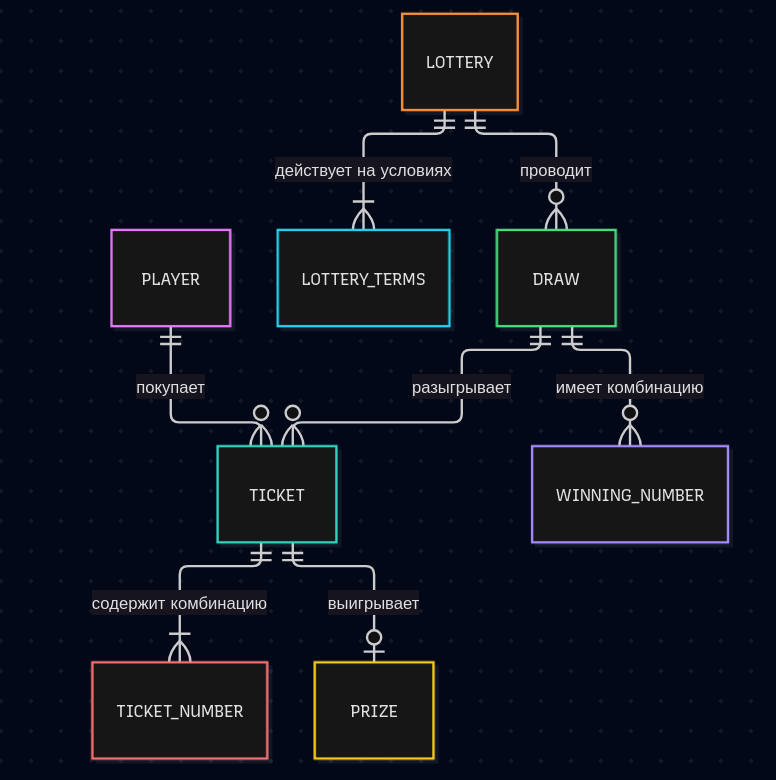

| Сущность | Смысл |
|---|---|
| PLAYER (Игрок) | зарегистрированный пользователь, покупатель билетов |
| LOTTERY (Лотерея) | продукт оператора: формат «k из N», период работы |
| LOTTERY_TERMS (Условия лотереи) | версия условий: цена билета и доля выручки в джекпот на интервале времени |
| DRAW (Тираж) | конкретный розыгрыш лотереи в назначенное время |
| WINNING_NUMBER (Выигрышное число) | число из выпавшей комбинации тиража |
| TICKET (Билет) | ставка игрока на тираж |
| TICKET_NUMBER (Число билета) | число, выбранное игроком в билете |
| PRIZE (Приз) | выигрыш по билету и состояние его выплаты |

Ключевые правила: билет относится ровно к одному тиражу и одному игроку; на билет начисляется не больше одного приза; у лотереи в каждый момент действует ровно одна версия условий.

### 2. Логическая модель

Таблицы, атрибуты, первичные и внешние ключи, схема в 3НФ.

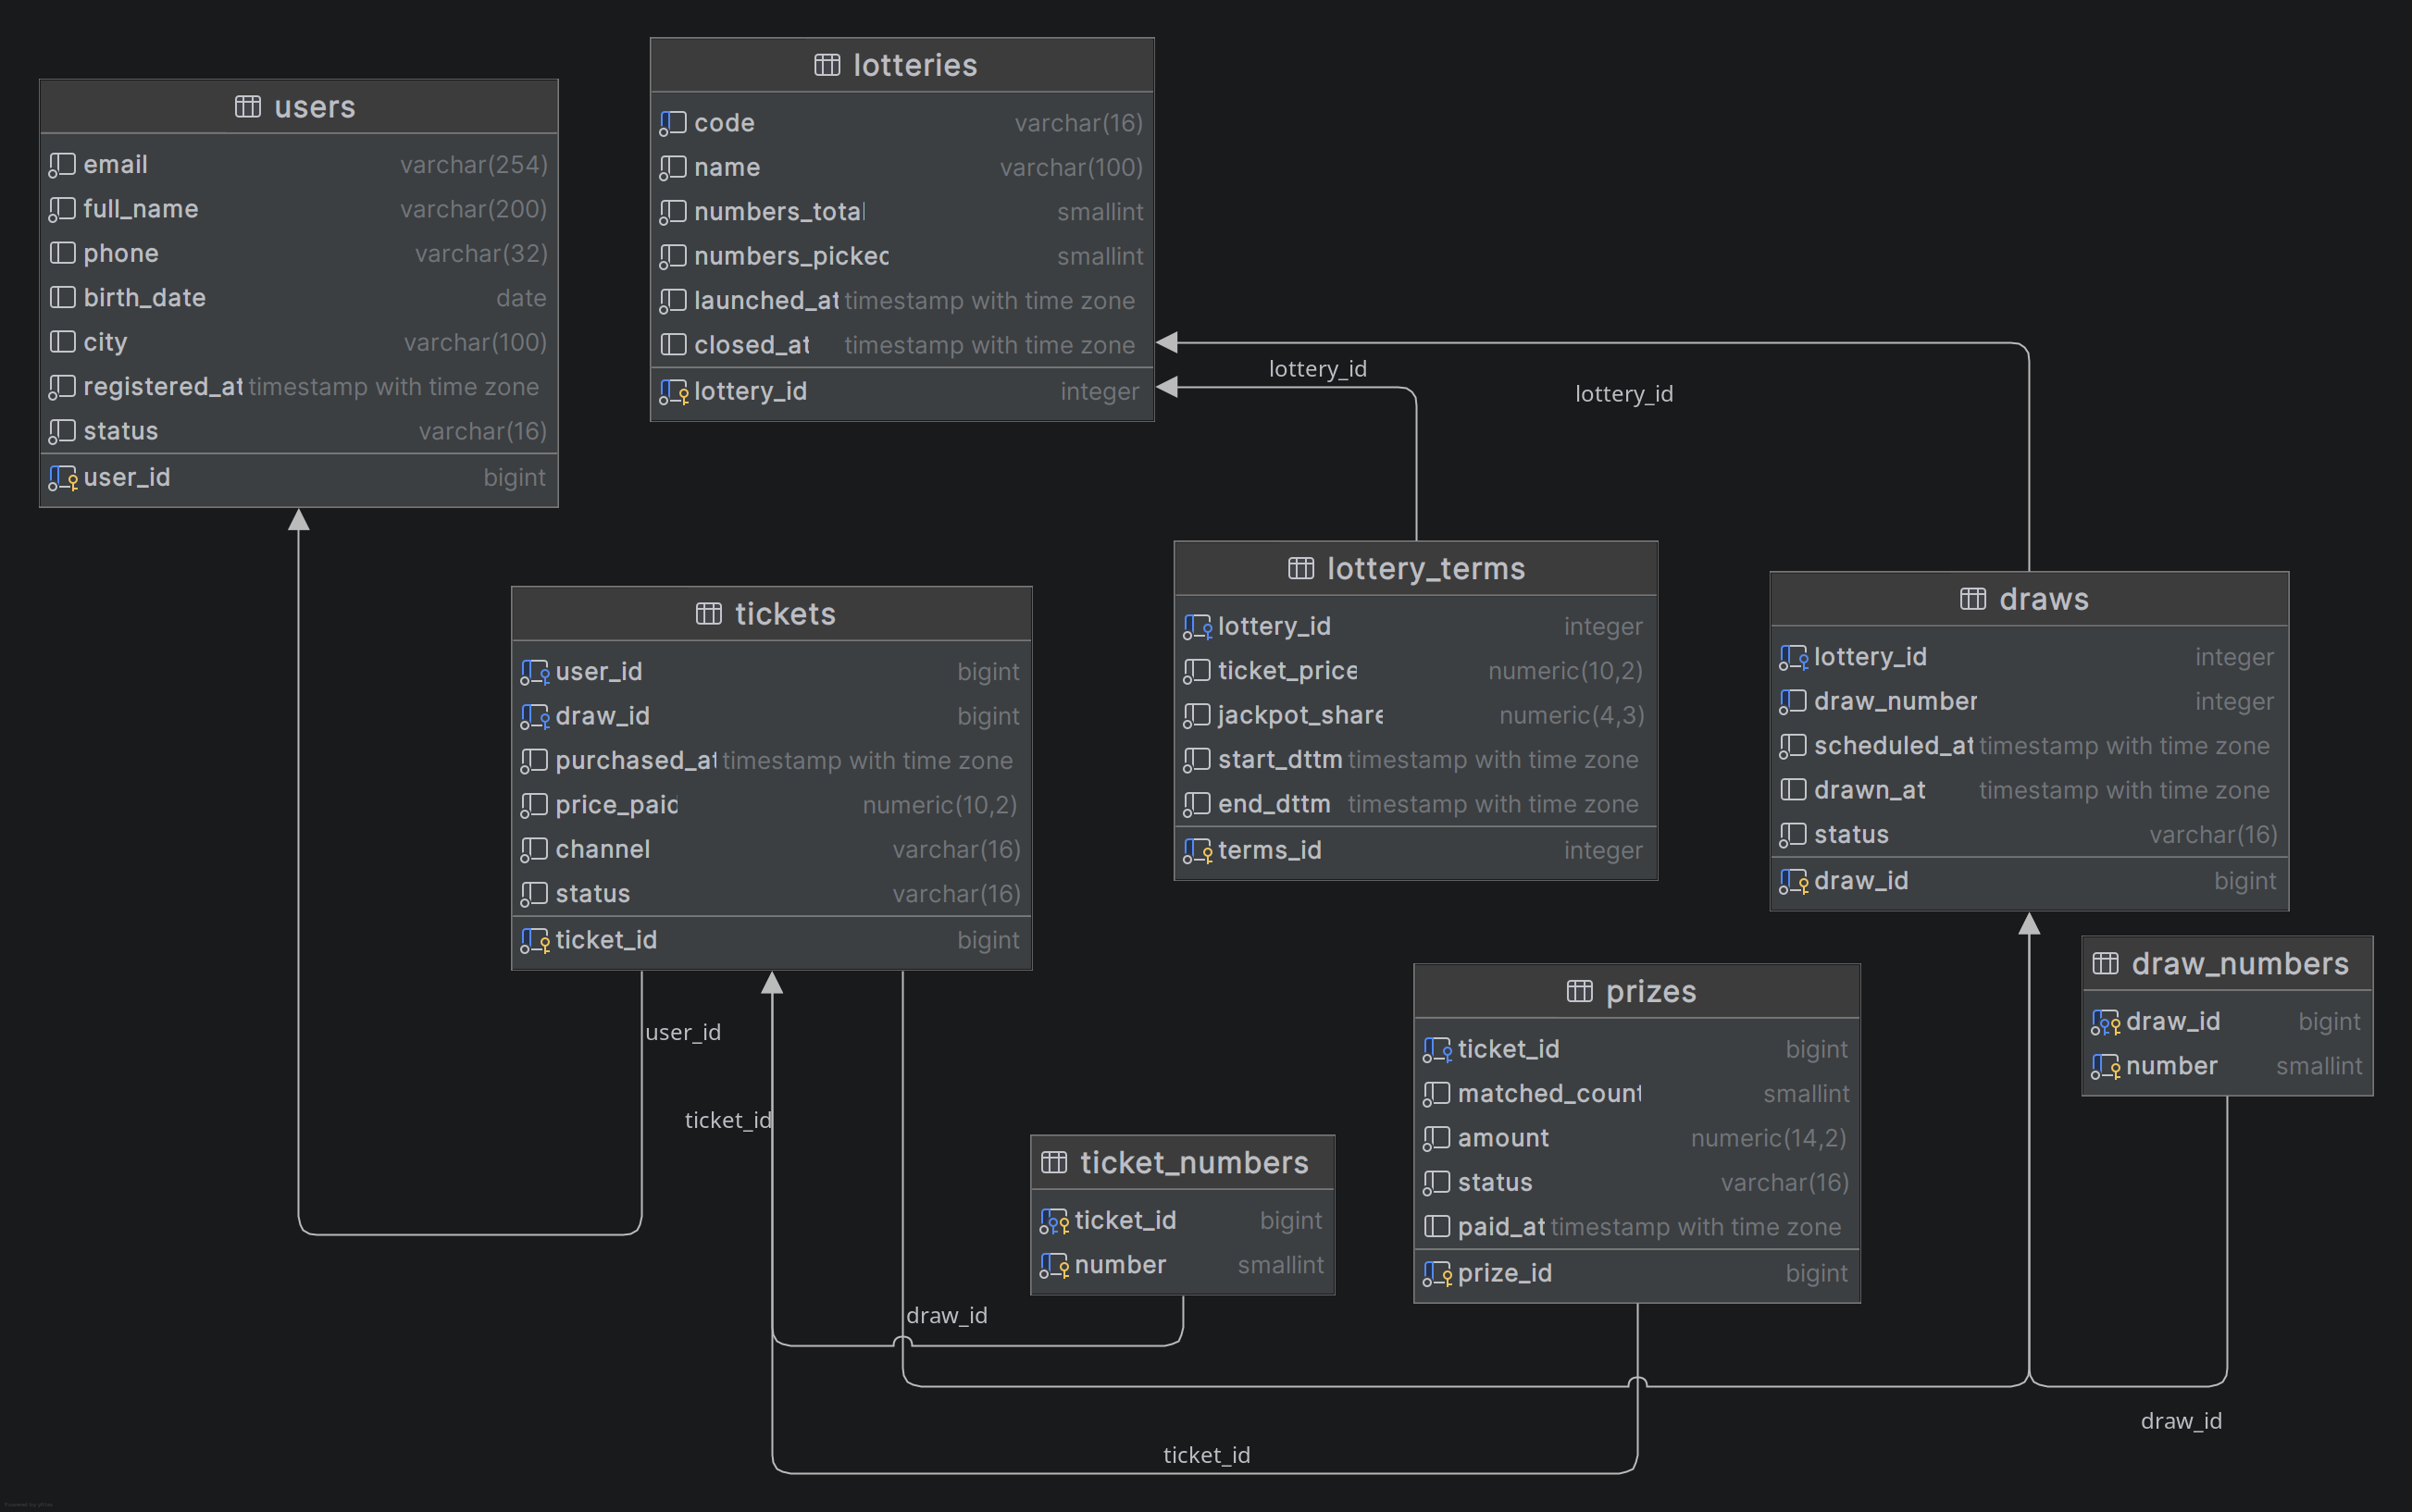

Лотерея билета определяется через тираж (`tickets.draw_id -> draws.lottery_id`), поэтому `lottery_id` в `tickets` не дублируется. Цена билета на момент покупки берётся из версии `lottery_terms`, а фактически уплаченная сумма `tickets.price_paid` хранится отдельно: это факт продажи, он может отличаться от цены по условиям из-за промоакций.

### 3. Физическая модель

Скрипт `lottery_project/lottery.sql`, PostgreSQL. Основные решения:

- суррогатные ключи `GENERATED BY DEFAULT AS IDENTITY`: при загрузке из CSV ключи приходят явно, после загрузки последовательности сдвигаются через `setval`;
- деньги в `numeric`, моменты времени в `timestamptz`;
- допустимые значения статусов и каналов закреплены `CHECK`, согласованность полей тоже: `drawn_at` заполнен ровно у проведённого тиража, `paid_at` ровно у выплаченного приза;
- SCD2 в `lottery_terms`: `CHECK (end_dttm > start_dttm)` и `EXCLUDE USING gist` по `(lottery_id, tstzrange(start_dttm, end_dttm))` запрещают пересечение версий одной лотереи на уровне БД;
- уникальность почты без учёта регистра - функциональным индексом по `lower(email)`;
- индексы на внешние ключи `tickets.user_id` и `tickets.draw_id`, по которым идут все аналитические соединения.

In [1]:
from pathlib import Path

PROJECT_DIR = Path("lottery_project")
SQL_SCRIPT_PATH = PROJECT_DIR / "lottery.sql"

print(SQL_SCRIPT_PATH.read_text(encoding="utf-8"))

-- Физическая модель БД лотерейного оператора (PostgreSQL 14+).
-- Запуск из каталога со скриптом: psql -v ON_ERROR_STOP=1 -f lottery.sql
-- Скрипт пересоздаёт таблицы, затем грузит CSV из каталога data.

BEGIN;

DROP TABLE IF EXISTS prizes, ticket_numbers, tickets, draw_numbers, draws, lottery_terms, lotteries, users CASCADE;

-- EXCLUDE по (lottery_id, диапазон дат) требует btree_gist
CREATE EXTENSION IF NOT EXISTS btree_gist;

CREATE TABLE users (
    user_id       bigint GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    email         varchar(254) NOT NULL,
    full_name     varchar(200) NOT NULL,
    phone         varchar(32),
    birth_date    date,
    city          varchar(100),
    registered_at timestamptz  NOT NULL,
    status        varchar(16)  NOT NULL DEFAULT 'active',
    CONSTRAINT users_status_check CHECK (status IN ('active', 'blocked', 'deleted')),
    CONSTRAINT users_email_format_check CHECK (email LIKE '_%@_%._%')
);
-- Почта уникальна без учёта регистра: в анкета

### 4. Генерация данных

Скрипт `lottery_project/generate_data.py` моделирует два года работы оператора (с 01.11.2024 по 15.11.2026) и пишет CSV в `lottery_project/data/`. Данные согласованы с бизнес-логикой: билеты покупаются только после регистрации игрока и до начала тиража, цена берётся из версии условий на момент покупки, выигрыши считаются по реальному совпадению чисел билета с выпавшей комбинацией, джекпот копится из доли выручки и переносится, пока его не выиграют.

Специально заложенные ошибки, неточности и выбросы:

- город записан по-разному (`Москва`, `москва`, `г. Москва`, `Мск`, `СПб`, `Питер`) или не указан;
- телефоны в разных форматах (`+7 (9xx) ...`, `89xx...`, `8 9xx ...`), часть пустые;
- дата рождения пустая или заглушка `1900-01-01` из старой анкеты;
- часть почт записана заглавными буквами;
- активность игроков распределена по Парето: несколько игроков купили сотни и тысячи билетов, около 12% зарегистрированных не купили ни одного;
- промобилеты за полцены и бесплатные, поэтому `price_paid` иногда не совпадает с ценой по условиям;
- возвраты билетов: все билеты отменённых тиражей и случайные единичные возвраты;
- призы, которые ещё не выплачены (`pending`), и не востребованные за 180 дней (`expired`);
- будущие тиражи со статусом `scheduled`, на которые уже идут продажи; сезонная лотерея, закрытая в январе 2026.

In [2]:
%run lottery_project/generate_data.py

users=4000 lotteries=6 draws=1381 tickets=58135 prizes=5807


### 5. Загрузка в БД

Скрипт `lottery.sql` написан для `psql`. Чтобы выполнить его из ноутбука без дублирования DDL, обычный SQL отправляется как есть, а строки `\copy` превращаются в `COPY ... FROM STDIN` с передачей соответствующего CSV. Весь скрипт выполняется одной транзакцией (`BEGIN ... COMMIT` внутри него), при ошибке транзакция откатывается.

БД - локальный PostgreSQL 18 в docker: `docker run -d --name lottery-pg -p 127.0.0.1:55432:5432 -e POSTGRES_HOST_AUTH_METHOD=trust -e POSTGRES_DB=lottery -v lottery-pg-data:/var/lib/postgresql postgres:18-alpine`.

In [3]:
import re
from collections.abc import Iterable

import pandas as pd
import psycopg2  # noqa: F401
from IPython.display import display
from sqlalchemy import create_engine, text

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)

DATABASE_URL = "postgresql+psycopg2://postgres@localhost:55432/lottery"
engine = create_engine(
    DATABASE_URL, connect_args={"options": "-ctimezone=Europe/Moscow"}
)

PSQL_COPY_COMMAND = re.compile(
    r"\\copy\s+(?P<target>.+?)\s+from\s+'(?P<csv_path>[^']+)'\s+with\s+(?P<options>\(.+\))\s*;?",
    re.IGNORECASE,
)


def query(sql: str) -> pd.DataFrame:
    with engine.connect() as connection:
        return pd.read_sql_query(text(sql), connection)


def split_psql_script(script: str) -> Iterable[str | re.Match[str]]:
    """Делит psql-скрипт на куски обычного SQL и команды \\copy, сохраняя порядок."""
    sql_lines: list[str] = []
    for line in script.splitlines():
        copy_command = PSQL_COPY_COMMAND.fullmatch(line.strip())
        if copy_command is None:
            sql_lines.append(line)
            continue
        yield "\n".join(sql_lines)
        sql_lines = []
        yield copy_command
    yield "\n".join(sql_lines)


def run_psql_script(script_path: Path) -> None:
    connection = engine.raw_connection()
    connection.autocommit = True
    try:
        with connection.cursor() as cursor:
            for part in split_psql_script(script_path.read_text(encoding="utf-8")):
                if isinstance(part, str):
                    if part.strip():
                        cursor.execute(part)
                    continue
                csv_path = script_path.parent / part["csv_path"]
                with csv_path.open(encoding="utf-8") as csv_file:
                    cursor.copy_expert(
                        f"COPY {part['target']} FROM STDIN WITH {part['options']}",
                        csv_file,
                    )
                print(f"{part['target'].split()[0]}: загружено строк {cursor.rowcount}")
    except Exception:
        with connection.cursor() as cursor:
            cursor.execute("ROLLBACK")
        raise
    finally:
        connection.close()


run_psql_script(SQL_SCRIPT_PATH)

users: загружено строк 4000
lotteries: загружено строк 6
lottery_terms: загружено строк 12
draws: загружено строк 1381
draw_numbers: загружено строк 6234


tickets: загружено строк 58135


ticket_numbers: загружено строк 303816
prizes: загружено строк 5807


### 6. SCD2: версии условий лотерей

Каждая версия действует на полуинтервале `[start_dttm, end_dttm)`, у текущей версии `end_dttm = 9999-12-31 00:00:00+00`.

In [4]:
query("""
SELECT l.name, lt.terms_id, lt.ticket_price, lt.jackpot_share, lt.start_dttm, lt.end_dttm,
       lt.end_dttm = '9999-12-31 00:00:00+00' AS is_current
FROM lottery_terms AS lt
JOIN lotteries AS l USING (lottery_id)
ORDER BY l.lottery_id, lt.start_dttm
""")

,name,terms_id,ticket_price,jackpot_share,start_dttm,end_dttm,is_current
0,Быстрые 4 из 20,1,50.0,0.20,2024-10-31 21:00:00+00:00,2025-03-31 21:00:00+00:00,False
1,Быстрые 4 из 20,2,60.0,0.20,2025-03-31 21:00:00+00:00,2026-01-31 21:00:00+00:00,False
2,Быстрые 4 из 20,3,80.0,0.18,2026-01-31 21:00:00+00:00,9999-12-31 00:00:00+00:00,True
3,Спортлото 5 из 36,4,80.0,0.20,2024-10-31 21:00:00+00:00,2025-09-14 21:00:00+00:00,False
4,Спортлото 5 из 36,5,100.0,0.22,2025-09-14 21:00:00+00:00,9999-12-31 00:00:00+00:00,True
5,Гослото 6 из 45,6,100.0,0.25,2024-10-31 21:00:00+00:00,2025-05-31 21:00:00+00:00,False
6,Гослото 6 из 45,7,150.0,0.25,2025-05-31 21:00:00+00:00,2026-05-31 21:00:00+00:00,False
7,Гослото 6 из 45,8,150.0,0.30,2026-05-31 21:00:00+00:00,9999-12-31 00:00:00+00:00,True
8,Мега 7 из 49,9,150.0,0.30,2024-10-31 21:00:00+00:00,9999-12-31 00:00:00+00:00,True
9,Ночной экспресс 4 из 20,10,40.0,0.15,2025-05-31 21:00:00+00:00,9999-12-31 00:00:00+00:00,True


Point-in-time соединение: для каждого билета находится версия условий, действовавшая в момент покупки. Расхождение уплаченной суммы с ценой по условиям - это промобилеты.

In [5]:
query("""
SELECT l.name,
       lt.ticket_price AS terms_price,
       count(*) AS tickets_count,
       count(*) FILTER (WHERE t.price_paid = lt.ticket_price) AS full_price_count,
       count(*) FILTER (WHERE t.price_paid < lt.ticket_price) AS promo_count
FROM tickets AS t
JOIN draws AS d USING (draw_id)
JOIN lotteries AS l USING (lottery_id)
JOIN lottery_terms AS lt
  ON lt.lottery_id = d.lottery_id
 AND t.purchased_at >= lt.start_dttm
 AND t.purchased_at < lt.end_dttm
GROUP BY l.lottery_id, l.name, lt.terms_id, lt.ticket_price
ORDER BY l.lottery_id, lt.terms_id
""")

,name,terms_price,tickets_count,full_price_count,promo_count
0,Быстрые 4 из 20,50.0,1858,1813,45
1,Быстрые 4 из 20,60.0,3939,3854,85
2,Быстрые 4 из 20,80.0,3784,3700,84
3,Спортлото 5 из 36,80.0,6168,6014,154
4,Спортлото 5 из 36,100.0,8299,8112,187
5,Гослото 6 из 45,100.0,3820,3725,95
6,Гослото 6 из 45,150.0,5573,5454,119
7,Гослото 6 из 45,150.0,2621,2558,63
8,Мега 7 из 49,150.0,9657,9447,210
9,Ночной экспресс 4 из 20,40.0,10511,10249,262


### 7. `select * from ... limit 100` из всех таблиц

In [6]:
TABLES = [
    "users",
    "lotteries",
    "lottery_terms",
    "draws",
    "draw_numbers",
    "tickets",
    "ticket_numbers",
    "prizes",
]

for table in TABLES:
    print(table)
    display(query(f"SELECT * FROM {table} LIMIT 100"))

users


,user_id,email,full_name,phone,birth_date,city,registered_at,status
0,1,makarova_2002_1@yandex.ru,Макарова Людмила,89999196790,2000-05-14,Краснодар,2026-02-28 06:25:34.770885+00:00,active
1,2,petrov_2005_2@gmail.com,Петров Юрий,89174736956,1954-02-04,Санкт-Петербург,2026-06-24 02:06:14.877653+00:00,active
2,3,alekseeva.polina3@rambler.ru,Алексеева Полина,8 904 517 91 22,1968-08-10,Владивосток,2026-09-11 22:16:44.911675+00:00,active
3,4,YNIKOLAEVA4@RAMBLER.RU,Николаева Юлия,89397924791,1947-02-22,Москва,2024-08-08 05:53:06.979287+00:00,active
4,5,ppopova5@inbox.ru,Попова Полина,+7 (914) 782-85-59,1971-11-20,Санкт-Петербург,2025-05-13 10:21:32.786761+00:00,active
5,6,vivanov6@yandex.ru,Иванов Виктор,NaN,1999-08-01,СПб,2026-10-17 19:04:32.628929+00:00,active
6,7,nvasilev7@mail.ru,Васильев Никита,+7 (962) 123-52-40,2006-05-19,Санкт-Петербург,2025-02-27 01:17:02.257137+00:00,active
7,8,andreev_2007_8@yandex.ru,Андреев Роман,+79634412267,2004-04-07,Москва,2025-05-07 08:46:44.982040+00:00,active
8,9,petrova.yuliya9@gmail.com,Петрова Юлия,NaN,1965-10-18,Екатеринбург,2026-05-13 06:32:20.572050+00:00,active
9,10,akozlov10@bk.ru,Козлов Андрей,+79938741785,1995-02-05,г. Москва,2026-05-10 00:07:47.596358+00:00,active


lotteries


,lottery_id,code,name,numbers_total,numbers_picked,launched_at,closed_at
0,1,QUICK420,Быстрые 4 из 20,20,4,2024-10-31 21:00:00+00:00,NaT
1,2,SPORT536,Спортлото 5 из 36,36,5,2024-10-31 21:00:00+00:00,NaT
2,3,GOS645,Гослото 6 из 45,45,6,2024-10-31 21:00:00+00:00,NaT
3,4,MEGA749,Мега 7 из 49,49,7,2024-10-31 21:00:00+00:00,NaT
4,5,NIGHT420,Ночной экспресс 4 из 20,20,4,2025-05-31 21:00:00+00:00,NaT
5,6,NY645,Новогодняя 6 из 45,45,6,2024-10-31 21:00:00+00:00,2026-01-14 21:00:00+00:00


lottery_terms


,terms_id,lottery_id,ticket_price,jackpot_share,start_dttm,end_dttm
0,1,1,50.0,0.20,2024-10-31 21:00:00+00:00,2025-03-31 21:00:00+00:00
1,2,1,60.0,0.20,2025-03-31 21:00:00+00:00,2026-01-31 21:00:00+00:00
2,3,1,80.0,0.18,2026-01-31 21:00:00+00:00,9999-12-31 00:00:00+00:00
3,4,2,80.0,0.20,2024-10-31 21:00:00+00:00,2025-09-14 21:00:00+00:00
4,5,2,100.0,0.22,2025-09-14 21:00:00+00:00,9999-12-31 00:00:00+00:00
5,6,3,100.0,0.25,2024-10-31 21:00:00+00:00,2025-05-31 21:00:00+00:00
6,7,3,150.0,0.25,2025-05-31 21:00:00+00:00,2026-05-31 21:00:00+00:00
7,8,3,150.0,0.30,2026-05-31 21:00:00+00:00,9999-12-31 00:00:00+00:00
8,9,4,150.0,0.30,2024-10-31 21:00:00+00:00,9999-12-31 00:00:00+00:00
9,10,5,40.0,0.15,2025-05-31 21:00:00+00:00,9999-12-31 00:00:00+00:00


... (6 outputs left out)

ticket_numbers


,ticket_id,number
0,1,3
1,1,15
2,1,17
3,1,19
4,2,5
5,2,7
6,2,10
7,2,18
8,3,3
9,3,6


prizes


,prize_id,ticket_id,matched_count,amount,status,paid_at
0,1,2,2,50.0,paid,2024-11-01 18:33:44+00:00
1,2,14,3,1000.0,paid,2024-11-01 18:21:44+00:00
2,3,22,2,50.0,paid,2024-11-03 18:35:41+00:00
3,4,27,2,50.0,paid,2024-11-03 18:27:41+00:00
4,5,43,2,50.0,paid,2024-11-05 18:41:19+00:00
5,6,52,2,50.0,paid,2024-11-05 18:16:19+00:00
6,7,61,3,1000.0,paid,2024-11-07 18:34:10+00:00
7,8,62,2,50.0,paid,2024-11-07 18:36:10+00:00
8,9,65,2,50.0,paid,2024-11-07 18:34:10+00:00
9,10,68,2,50.0,paid,2024-11-07 18:15:10+00:00


### 8. `select count(*) from ...` из всех таблиц

In [7]:
query(
    " UNION ALL ".join(
        f"SELECT '{table}' AS table_name, count(*) AS rows_count FROM {table}"
        for table in TABLES
    )
)

,table_name,rows_count
0,lotteries,6
1,lottery_terms,12
2,draws,1381
3,draw_numbers,6234
4,prizes,5807
5,users,4000
6,tickets,58135
7,ticket_numbers,303816


### 9. Аналитический запрос

**Что считается выигрышем.** Учитываются призы со статусами `paid` и `pending`: начисленный, но ещё не полученный приз - это обязательство оператора. Призы `expired` (не востребованы за 180 дней) остаются у оператора и в выигрыш не входят.

#### 9.1. Средняя сумма выигрыша по пользователям

Для каждого выигравшего игрока: число призов, общая сумма, средний приз. `percent_rank` показывает, какую долю игроков данный игрок опережает по среднему выигрышу, `ntile(10)` - его дециль.

In [8]:
query("""
WITH user_winnings AS (
    SELECT t.user_id,
           count(*) AS prizes_count,
           sum(p.amount) AS total_won,
           avg(p.amount) AS avg_prize
    FROM prizes AS p
    JOIN tickets AS t USING (ticket_id)
    WHERE p.status <> 'expired'
    GROUP BY t.user_id
)
SELECT uw.user_id,
       u.full_name,
       uw.prizes_count,
       uw.total_won,
       round(uw.avg_prize, 2) AS avg_prize,
       round((percent_rank() OVER (ORDER BY uw.avg_prize) * 100)::numeric, 1) AS avg_prize_percentile,
       ntile(10) OVER (ORDER BY uw.avg_prize) AS avg_prize_decile
FROM user_winnings AS uw
JOIN users AS u USING (user_id)
ORDER BY uw.avg_prize DESC, uw.user_id
""")

,user_id,full_name,prizes_count,total_won,avg_prize,avg_prize_percentile,avg_prize_decile
0,1935,Петрова Ольга,2,75100.0,37550.00,100.0,10
1,1307,Андреев Максим,3,97591.0,32530.33,99.9,10
2,3181,Никитин Виктор,3,75140.0,25046.67,99.9,10
3,3409,Морозова Юлия,1,24000.0,24000.00,99.8,10
4,596,Павлов Александр,3,52185.0,17395.00,99.8,10
...,...,...,...,...,...,...,...
1936,3965,Васильева Юлия,3,120.0,40.00,0.0,2
1937,3971,Михайлова Ирина,1,40.0,40.00,0.0,2
1938,3985,Степанов Виктор,1,40.0,40.00,0.0,1
1939,3987,Андреев Алексей,1,40.0,40.00,0.0,1


#### 9.2. Распределение среднего выигрыша по перцентилям

In [9]:
query("""
WITH user_winnings AS (
    SELECT t.user_id, avg(p.amount) AS avg_prize
    FROM prizes AS p
    JOIN tickets AS t USING (ticket_id)
    WHERE p.status <> 'expired'
    GROUP BY t.user_id
)
SELECT count(*) AS winners_count,
       round(avg(avg_prize), 2) AS mean_avg_prize,
       round(min(avg_prize), 2) AS min_avg_prize,
       percentile_cont(0.25) WITHIN GROUP (ORDER BY avg_prize)::numeric(14, 2) AS p25,
       percentile_cont(0.50) WITHIN GROUP (ORDER BY avg_prize)::numeric(14, 2) AS p50,
       percentile_cont(0.75) WITHIN GROUP (ORDER BY avg_prize)::numeric(14, 2) AS p75,
       percentile_cont(0.90) WITHIN GROUP (ORDER BY avg_prize)::numeric(14, 2) AS p90,
       percentile_cont(0.95) WITHIN GROUP (ORDER BY avg_prize)::numeric(14, 2) AS p95,
       percentile_cont(0.99) WITHIN GROUP (ORDER BY avg_prize)::numeric(14, 2) AS p99,
       round(max(avg_prize), 2) AS max_avg_prize
FROM user_winnings
""")

,winners_count,mean_avg_prize,min_avg_prize,p25,p50,p75,p90,p95,p99,max_avg_prize
0,1941,409.92,40.0,60.0,90.0,410.0,852.86,1500.0,3050.0,37550.0


#### 9.3. Прибыль по лотереям с ранжированием

Поступления - сумма `price_paid` по проданным билетам (возвраты исключены). Призы - начисленные невостребованные и выплаченные призы. Лотереи ранжируются по абсолютной прибыли (`profit_rank`) и по марже (`margin_rank`); `profit_share_pct` - доля лотереи в общей прибыли оператора.

In [10]:
query("""
WITH ticket_revenue AS (
    SELECT d.lottery_id, count(*) AS tickets_sold, sum(t.price_paid) AS revenue
    FROM tickets AS t
    JOIN draws AS d USING (draw_id)
    WHERE t.status = 'sold'
    GROUP BY d.lottery_id
),
prize_payouts AS (
    SELECT d.lottery_id, count(*) AS prizes_count, sum(p.amount) AS payouts
    FROM prizes AS p
    JOIN tickets AS t USING (ticket_id)
    JOIN draws AS d USING (draw_id)
    WHERE p.status <> 'expired'
    GROUP BY d.lottery_id
),
lottery_profit AS (
    SELECT l.lottery_id,
           l.name,
           coalesce(r.tickets_sold, 0) AS tickets_sold,
           coalesce(r.revenue, 0) AS revenue,
           coalesce(pp.prizes_count, 0) AS prizes_count,
           coalesce(pp.payouts, 0) AS payouts,
           coalesce(r.revenue, 0) - coalesce(pp.payouts, 0) AS profit
    FROM lotteries AS l
    LEFT JOIN ticket_revenue AS r USING (lottery_id)
    LEFT JOIN prize_payouts AS pp USING (lottery_id)
)
SELECT rank() OVER (ORDER BY profit DESC) AS profit_rank,
       name,
       tickets_sold,
       revenue,
       prizes_count,
       payouts,
       profit,
       round(profit / nullif(revenue, 0) * 100, 1) AS margin_pct,
       rank() OVER (ORDER BY profit / nullif(revenue, 0) DESC NULLS LAST) AS margin_rank,
       round(profit / nullif(sum(profit) OVER (), 0) * 100, 1) AS profit_share_pct
FROM lottery_profit
ORDER BY profit_rank, name
""")

,profit_rank,name,tickets_sold,revenue,prizes_count,payouts,profit,margin_pct,margin_rank,profit_share_pct
0,1,Гослото 6 из 45,11955,1582200.0,274,450500.0,1131700.0,71.5,2,33.3
1,2,Мега 7 из 49,9628,1426350.0,460,630450.0,795900.0,55.8,4,23.4
2,3,Спортлото 5 из 36,14411,1301070.0,1824,560920.0,740150.0,56.9,3,21.8
3,4,Новогодняя 6 из 45,1898,478700.0,41,95800.0,382900.0,80.0,1,11.3
4,5,Быстрые 4 из 20,9490,617820.0,1507,418836.0,198984.0,32.2,6,5.8
5,6,Ночной экспресс 4 из 20,10440,411580.0,1653,258526.0,153054.0,37.2,5,4.5


### Состав архива для LMS

1. Скриншоты концептуальной (`lottery_project/conceptual_schema.png`) и логической (`lottery_project/logical_schema.png`) схем.
2. `lottery_project/data/*.csv` - сгенерированные данные.
3. `lottery_project/generate_data.py` - файл генерации данных.
4. `lottery_project/lottery.sql` - DDL и загрузка данных.